# EEG analysis pipeline - SmartickDataset (76 subjects)

Phased pipeline. Supersedes the single-subject exploration in `read_eeg.ipynb`.

* **Phase 0** manifest, file integrity, recording-level quality
* **Phase A** preprocessing (median reference, 1-45 Hz) + automated bad channels
* **Phase B** band power from artifact-rejected segments, every recording
* **Phase C** math-only evoked contrast (act1 vs act2, 20 trials/subject)

## Design (verified from the `.set` headers)

| domain | run | condition | trials |
|---|---|---|---|
| read | 1 | basal rest | 0 |
| read | 2 | act (reading) | 2-3 |
| math | 1 | basal rest | 0 |
| math | 2 | act1 | 20 |
| math | 3 | act2 | 20 (math only) |

`ses-1` = PRE, `ses-2` = POST.

## Two empirical findings that drive the design

**1. Median reference, not average reference.** These recordings contain extreme
artifacts (a few channels reach SD > 7000 uV). Because the across-channel mean has
SD ~263 uV, subtracting it injects a large common-mode component into *every*
channel and inflates median per-channel SD from 33 uV to 261 uV. A median
reference is robust to those outlier channels and leaves median SD at ~27 uV.

**2. The dataset is heavily artifact-contaminated.** Median per-channel SD across
the 364 readable recordings: p25 = 27 uV, p50 = 118 uV, p75 = 786 uV.
Only 173/364 are under 100 uV. Task runs are much worse than rest
(math act2 median 259 uV vs math basal 39 uV), so band power is computed on
artifact-rejected segments and the retained fraction is reported per recording.

No notch is applied: 50 and 60 Hz were tested for narrow peaks and both came back
at 1/f rolloff (peak/flank ratio 0.37-0.63).

In [1]:
import warnings, re, glob, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import mne
from scipy.signal import welch

warnings.filterwarnings("ignore")
mne.set_log_level("ERROR")
%matplotlib inline

def find_root(marker="32_Chs_Location.ced"):
    """Walk up from the kernel cwd so this notebook runs from anywhere."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / marker).exists():
            return base
    raise FileNotFoundError(f"project root marker not found: {marker}")

ROOT    = find_root()
RESULTS = ROOT / "analysis" / "results" / "eeg"
RESULTS.mkdir(parents=True, exist_ok=True)
CED     = ROOT / "32_Chs_Location.ced"
DESCR   = ROOT / "02_EEG_Data_Descriptor.xlsx"

# ---- run gates -------------------------------------------------------------
PILOT      = True      # True -> ~10 subjects, then STOP for review
PILOT_N    = 10
FULL_BATCH = False     # flip to True after the pilot is signed off
SUFFIX     = "_pilot" if PILOT else ""

# ---- signal ----------------------------------------------------------------
SFREQ    = 256.0
FILT_LO  = 1.0
FILT_HI  = 45.0
REF_MODE = "median"     # NOT "average" - see markdown
BANDS    = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 12),
            "sigma": (12, 16), "beta": (16, 30)}
N_FFT_SEC = 4.0
IAF_RANGE = (8.0, 13.0)

# ---- QC thresholds ---------------------------------------------------------
BAD_LOGZ      = 3.0      # robust z of log10(SD) across the recording's channels
DEAD_PTP_UV   = 1.0
SEG_SEC       = 4.0      # analysis segment length (= N_FFT_SEC, 0.25 Hz resolution)
REJECT_PTP_UV = 150.0    # segment rejection ceiling, any good channel
MIN_CLEAN     = 0.5      # recording flagged if it retains < this fraction
MIN_SEGMENTS  = 3        # need at least this many clean segments for a PSD

# ---- evoked ----------------------------------------------------------------
EPOCH_TMIN, EPOCH_TMAX = -0.3, 1.0
BASE_TMIN,  BASE_TMAX  = -0.2, 0.0
STIM_TRIGGERS          = ["33026", "33027", "33028"]
MIN_TRIALS             = 15

ROI = {
    "frontal":       ["FP1","FP2","F7","F3","Fz","F4","F8"],
    "frontocentral": ["FC5","FC1","FC2","FC6"],
    "central":       ["C3","Cz","C4"],
    "temporal":      ["T7","T8","FT10","FT9","TP9","TP10","P7","P8"],
    "parietal":      ["CP1","CP5","CP2","CP6","P3","Pz","P4"],
    "occipital":     ["O1","Oz","O2"],
}
assert sorted(sum(ROI.values(), [])) == sorted([
    "FP1","FP2","F7","F3","Fz","F4","F8","FT10","FT9","T7","FC5","C3","FC1","FC2",
    "FC6","C4","Cz","CP1","CP5","TP9","CP2","CP6","TP10","T8","P7","P3","Pz","P4",
    "P8","O1","Oz","O2"]), "ROI must partition all 32 channels"
print(f"config ok | PILOT={PILOT} REF={REF_MODE} bands={list(BANDS)}")

config ok | PILOT=True REF=median bands=['delta', 'theta', 'alpha', 'sigma', 'beta']


## Helpers

In [2]:
def load_montage():
    ced = pd.read_csv(CED, sep="\t")
    ced.columns = [c.strip() for c in ced.columns]
    ch = [str(l).strip() for l in ced["labels"]]
    # CED columns are (X=anterior, Y=left, Z=up); MNE head frame needs (X=left, Y=anterior, Z=up)
    pos = ced[["Y", "X", "Z"]].astype(float).values / 1000.0
    return mne.channels.make_dig_montage(ch_pos=dict(zip(ch, pos)), coord_frame="head")

MONTAGE = load_montage()

def read_set(path):
    """(raw, None) on success, (None, error_string) on failure."""
    try:
        return mne.io.read_raw_eeglab(str(path), preload=True, verbose=False), None
    except Exception as e:
        return None, f"{type(e).__name__}: {str(e)[:70]}"

def robust_log_z(x):
    """Robust z of log10(x) - stable when a few channels are orders of magnitude out."""
    l = np.log10(np.maximum(x, 1e-12))
    m = np.median(l)
    mad = np.median(np.abs(l - m))
    return (l - m) / (1.4826 * mad) if mad > 0 else np.zeros_like(l)

def prepare(raw_loaded):
    """Montage + robust re-reference + bandpass. Returns a filtered copy."""
    raw = raw_loaded.copy()
    raw.rename_channels({"FP1": "Fp1", "FP2": "Fp2"})
    raw.set_montage(MONTAGE, on_missing="raise")
    if REF_MODE == "median":
        d = raw.get_data()
        raw._data = d - np.median(d, axis=0, keepdims=True)
    else:
        raw.set_eeg_reference(REF_MODE, projection=False)
    raw.filter(l_freq=FILT_LO, h_freq=FILT_HI, method="fir",
               phase="zero", verbose=False)
    return raw

def mark_bads(raw):
    """Flag bad channels on a prepared raw using the recording's own statistics."""
    d = raw.get_data() * 1e6
    sd, ptp = d.std(axis=1), np.ptp(d, axis=1)
    bad = (robust_log_z(sd) > BAD_LOGZ) | (ptp < DEAD_PTP_UV)
    raw.info["bads"] = list(np.array(raw.ch_names)[bad])
    return sd, ptp, bad

print("helpers ready | montage ch:", len(MONTAGE.ch_names))

helpers ready | montage ch: 32


## Phase 0 - manifest, integrity, recording-level quality

`usable_bands` and `usable_evoked` are tracked separately: reading run-2 has only
2-3 trials so it is excluded from Phase C but still valid for Phase B.

In [3]:
def parse_sidecar(path):
    p = Path(str(path).replace("_eeg.set", "_events.tsv"))
    if not p.exists():
        return 0
    d = pd.read_csv(p, sep="\t")
    return int(d["value"].astype(str).isin(STIM_TRIGGERS).sum())

def build_manifest():
    rows = []
    for f in sorted(glob.glob(str(ROOT / "sub-*" / "ses-*" / "eeg" / "*_eeg.set"))):
        p = Path(f)
        sid, ses = p.parts[-4].replace("sub-", ""), p.parts[-3]
        run = re.search(r"_run-(\d+)_eeg\.set$", p.name).group(1)
        grp = sid[:2]
        domain = "read" if grp in ("Rc", "Re") else "math"
        rows.append(dict(
            subject=sid, session=ses, phase="PRE" if ses == "ses-1" else "POST",
            run=int(run),
            group={"Mc":"MathCtrl","Me":"MathExp","Rc":"ReadCtrl","Re":"ReadExp"}[grp],
            domain=domain,
            condition={1:"basal", 2:"act1" if domain=="math" else "act", 3:"act2"}[int(run)],
            task="rest" if run == "1" else "task",
            n_stim=parse_sidecar(f), size_mb=p.stat().st_size / 1e6, path=str(p)))
    return pd.DataFrame(rows)

def load_descriptor():
    """PRE/POST availability per run. Column names vary ('EEG B2 .1'), so keys
    are normalised by stripping spaces before the .1 session suffix."""
    spec = {"Reading_Data_Available": {1: "EEG Baseline", 2: "EEG Reading"},
            "Math_Data_Available":    {1: "EEG Baseline", 2: "EEG B1", 3: "EEG B2"}}
    out = {}
    for sheet, cols in spec.items():
        d = pd.ExcelFile(DESCR).parse(sheet, header=1).dropna(how="all")
        norm = {re.sub(r"\s+", "", str(c)): c for c in d.columns}
        for _, r in d.iterrows():
            sid = str(r["Subject"]).replace("sub-", "")
            if not re.fullmatch(r"[A-Za-z]{2}\d+", sid):
                continue
            for run, col in cols.items():
                for phase, suf in (("PRE", ""), ("POST", ".1")):
                    key = re.sub(r"\s+", "", col) + suf
                    if key in norm:
                        out[(sid, run, phase)] = str(r[norm[key]]).strip().upper()
    return out

man = build_manifest()
desc = load_descriptor()
man["desc_available"] = [desc.get((s, r, p), "")
                         for s, r, p in zip(man.subject, man.run, man.phase)]
man["desc_matched"] = man.desc_available != ""
print(f"manifest: {len(man)} recordings | descriptor rows matched: {man.desc_matched.sum()}")
print(man.desc_available.value_counts().to_string())

manifest: 366 recordings | descriptor rows matched: 366
desc_available
YES    366


In [4]:
# per-recording integrity + quality gate (cheap: median reference, no filtering)
def rec_quality(raw_loaded):
    """Median per-channel SD after 1-45 Hz filtering, over channels that are not
    bad. This is the gate metric: raw SD is dominated by a few huge artifacts."""
    raw = prepare(raw_loaded)
    mark_bads(raw)
    d = raw.get_data() * 1e6
    sd = d.std(axis=1)
    good = sd < (np.median(sd) * 10)
    return float(np.median(sd[good])) if good.any() else np.nan

t0 = time.time()
rows = []
for r in man.itertuples():
    rec = dict(subject=r.subject, session=r.session, run=r.run, loadable=False,
               error="", n_times=np.nan, duration_s=np.nan, med_sd_uv=np.nan)
    raw, err = read_set(r.path)
    if raw is None:
        rec["error"] = err
    else:
        rec.update(loadable=True, n_times=raw.n_times,
                   duration_s=raw.n_times / raw.info["sfreq"],
                   med_sd_uv=rec_quality(raw))
    rows.append(rec)
man = man.merge(pd.DataFrame(rows), on=["subject", "session", "run"], how="left")

man["exclusion_reason"] = ""
man.loc[~man.loadable, "exclusion_reason"] = "unreadable file"
man.loc[man.desc_available == "NO", "exclusion_reason"] = "descriptor: not available"
man.loc[man.med_sd_uv > 200, "exclusion_reason"] = np.where(
    man.loc[man.med_sd_uv > 200, "exclusion_reason"] == "",
    "recording quality: median SD > 200 uV", "")

# a subject enters PRE/POST contrasts only if both sessions survive QC
ok_runs = man[man.loadable & (man.exclusion_reason == "")]
pair_ok = (ok_runs.groupby(["subject", "run"]).phase.nunique() == 2).rename("both_sessions")
man = man.merge(pair_ok, on=["subject", "run"], how="left")
man["both_sessions"] = man.both_sessions.fillna(False)

man["usable_bands"]  = man.loadable & (man.exclusion_reason == "")
man["usable_evoked"] = man.usable_bands & (man.n_stim >= MIN_TRIALS) & (man.domain == "math")
man.to_csv(RESULTS / f"manifest{SUFFIX}.csv", index=False)
print(f"probe {time.time()-t0:.1f}s")
print(f"usable_bands  : {man.usable_bands.sum()} / {len(man)}")
print(f"usable_evoked : {man.usable_evoked.sum()} / {len(man)}")

probe 16.1s
usable_bands  : 235 / 366
usable_evoked : 89 / 366


In [5]:
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 100)
print("--- design matrix ---")
print(pd.crosstab([man.domain, man.condition], [man.group, man.phase]).to_string())
print()
print("--- recording quality (median per-channel SD, uV) ---")
print(man[man.loadable].groupby(["domain", "condition"]).med_sd_uv.agg(
    n="size", median="median", under_100=lambda s: int((s < 100).sum()),
    under_200=lambda s: int((s < 200).sum())).round(1).to_string())
print()
print("--- exclusions ---")
print(man.loc[man.exclusion_reason != "", "exclusion_reason"].value_counts().to_string()
      if (man.exclusion_reason != "").any() else "  none")
print()
print("--- unreadable / truncated ---")
print(man.loc[~man.loadable, ["subject","session","run","size_mb","error"]].to_string(index=False))
print()
print("--- task runs below MIN_TRIALS (excluded from Phase C only) ---")
low = man[(man.task == "task") & (man.n_stim < MIN_TRIALS)]
print(low.groupby(["domain", "run"]).size().to_string())

--- design matrix ---
group            MathCtrl     MathExp     ReadCtrl     ReadExp    
phase                POST PRE    POST PRE     POST PRE    POST PRE
domain condition                                                  
math   act1            18  21      19  19        0   0       0   0
       act2            18  21      19  19        0   0       0   0
       basal           18  21      19  19        0   0       0   0
read   act              0   0       0   0       16  13      19  17
       basal            0   0       0   0       16  16      19  19

--- recording quality (median per-channel SD, uV) ---
                   n  median  under_100  under_200
domain condition                                  
math   act1       77    99.7         39         47
       act2       77   133.3         37         42
       basal      77    30.6         49         56
read   act        64    57.8         37         41
       basal      69    30.4         43         49

--- exclusions ---
exclusion_

## Phase A - preprocessing and channel QC

Bad channels are detected per recording from robust statistics across that
recording's own channels. Nothing is hard-coded per subject.

In [6]:
def qc_one(raw_loaded):
    """Returns (qc DataFrame, prepared raw). Bad channels are marked on raw.info."""
    raw = prepare(raw_loaded)
    d = raw.get_data() * 1e6
    sd, ptp = d.std(axis=1), np.ptp(d, axis=1)
    z = robust_log_z(sd)
    bad = (z > BAD_LOGZ) | (ptp < DEAD_PTP_UV)
    qc = pd.DataFrame(dict(ch=raw.ch_names, sd_uV=sd, ptp_uV=ptp, log_z=z, bad=bad,
                           reason=np.where(ptp < DEAD_PTP_UV, "dead",
                                   np.where(z > BAD_LOGZ, "sd-outlier", ""))))
    if bad.any():
        raw.info["bads"] = list(np.array(raw.ch_names)[bad])
    return qc, raw

print("qc_one ready")

qc_one ready


In [7]:
if PILOT:
    per = (PILOT_N + 3) // 4  # ceil
    keep = []
    for g in ["Rc", "Re", "Mc", "Me"]:
        sset = sorted(man.loc[man.subject.str.startswith(g), "subject"].unique())
        keep += sset[:per]
    keep = keep[:PILOT_N]
    target = man[man.subject.isin(keep)]
else:
    target = man[man.usable_bands]
target.to_csv(RESULTS / f"pilot_target{SUFFIX}.csv", index=False)
analysis_target = target[target.usable_bands].copy()
analysis_target.to_csv(RESULTS / f"analysis_target{SUFFIX}.csv", index=False)
print(f"Phase A target: {target.subject.nunique()} subjects, {len(target)} recordings")
print(f"quality-gated (used by Phases B/C): {len(analysis_target)} recordings "
      f"({target.subject.nunique()} subjects seen)")

t0, chq, recq = time.time(), [], []
for r in target.itertuples():
    raw, err = read_set(r.path)
    if raw is None:
        recq.append(dict(subject=r.subject, session=r.session, run=r.run, status="unreadable"))
        continue
    qc, _ = qc_one(raw)
    qc.insert(0, "run", r.run); qc.insert(0, "session", r.session); qc.insert(0, "subject", r.subject)
    chq.append(qc)
    recq.append(dict(subject=r.subject, session=r.session, run=r.run, group=r.group,
                     domain=r.domain, condition=r.condition, phase=r.phase,
                     n_times=raw.n_times, duration_s=raw.n_times / raw.info["sfreq"],
                     n_bad=int(qc.bad.sum()), bad_ch="|".join(qc.loc[qc.bad, "ch"]),
                     pct_bad=100 * qc.bad.mean(), med_sd_uv=float(qc.sd_uV.median()),
                     n_stim=r.n_stim, status="ok"))
chq = pd.concat(chq, ignore_index=True)
recq = pd.DataFrame(recq)
chq.to_csv(RESULTS / f"qc_channels{SUFFIX}.csv", index=False)
recq.to_csv(RESULTS / f"qc_recordings{SUFFIX}.csv", index=False)
print(f"Phase A done in {time.time()-t0:.1f}s")


Phase A target: 10 subjects, 44 recordings
quality-gated (used by Phases B/C): 26 recordings (10 subjects seen)
Phase A done in 1.8s


In [8]:
ok = recq[recq.status == "ok"]
print("--- bad channels per recording ---")
print(ok.groupby(["domain", "condition"]).agg(
    n=("n_bad", "size"), bad_mean=("n_bad", "mean"), bad_max=("n_bad", "max"),
    pct_bad_mean=("pct_bad", "mean")).round(2).to_string())
print()
print("--- most frequently flagged channels ---")
bc = chq[chq.bad].groupby("ch").bad.sum().sort_values(ascending=False)
print(bc.head(12).to_string() if len(bc) else "  none flagged")
print()
print("--- cleanest vs worst recording in the pilot ---")
print(ok.nsmallest(3, "n_bad")[["subject","session","run","condition","n_bad","med_sd_uv"]].to_string(index=False))
print(ok.nlargest(3, "n_bad")[["subject","session","run","condition","n_bad","med_sd_uv"]].to_string(index=False))

--- bad channels per recording ---
                   n  bad_mean  bad_max  pct_bad_mean
domain condition                                     
math   act1        7      5.57        9         17.41
       act2        7      5.71        9         17.86
       basal       7      6.43        9         20.09
read   act        11      6.36        9         19.89
       basal      12      5.92       10         18.49

--- most frequently flagged channels ---
ch
TP10    37
P4      32
O1      28
Oz      27
CP1     26
O2      25
TP9     22
P8      18
CP6     15
T8      13
CP5      6
P3       4

--- cleanest vs worst recording in the pilot ---
subject session  run condition  n_bad   med_sd_uv
   Mc01   ses-1    2      act1      0  381.907231
   Mc02   ses-2    3      act2      0 1102.044447
   Rc02   ses-2    1     basal      0  835.653780
subject session  run condition  n_bad   med_sd_uv
   Rc03   ses-2    1     basal     10 2059.901570
   Mc02   ses-1    1     basal      9  113.304363
   Mc02   

## Phase B - band power on artifact-rejected segments

Each recording is cut into 2 s segments; segments where any good channel exceeds
150 uV peak-to-peak are dropped, and the Welch PSD is computed on what survives.
`clean_frac` is reported so the analysed N per cell is never implicit.

In [9]:
def band_power_one(raw):
    """Welch PSD on artifact-rejected segments. Returns (DataFrame per channel,
    clean_frac)."""
    segs = mne.make_fixed_length_epochs(raw, duration=SEG_SEC, preload=True,
                                        verbose=False)
    n_all = len(segs)
    if n_all == 0:
        return None, 0.0
    X = segs.get_data() * 1e6                           # n_seg x n_ch x n_t (uV)
    # Per-channel rejection. Rejecting a whole 4 s window whenever ANY channel
    # shows a blink discards ~100% of windows even in clean recordings, because
    # blink artefacts recur every few seconds. Each channel instead keeps the
    # segments where that channel itself is clean.
    ptp = np.ptp(X, axis=2)                             # n_seg x n_ch
    clean = ptp <= REJECT_PTP_UV
    bad = set(raw.info["bads"])
    freqs, Pfull = welch(X, fs=raw.info["sfreq"], axis=-1,
                         nperseg=min(X.shape[-1], int(N_FFT_SEC * raw.info["sfreq"])))
    recs = []
    for i, ch in enumerate(raw.ch_names):
        if ch in bad:
            continue
        keep_seg = clean[:, i]
        if keep_seg.sum() < MIN_SEGMENTS:
            continue
        P = Pfull[keep_seg, i, :].mean(axis=0)           # uV^2/Hz for this channel
        r = dict(ch=ch, n_seg_kept=int(keep_seg.sum()),
                 clean_frac=float(keep_seg.mean()))
        tot = 0.0
        for b, (lo, hi) in BANDS.items():
            bm = (freqs >= lo) & (freqs < hi)
            v = float(P[bm].mean())
            r[f"{b}_abs"] = v
            tot += v
        for b in BANDS:
            r[f"{b}_rel"] = r[f"{b}_abs"] / tot if tot > 0 else np.nan
        am = (freqs >= IAF_RANGE[0]) & (freqs <= IAF_RANGE[1])
        r["iaf_hz"] = float(freqs[am][np.argmax(P[am])]) if am.any() else np.nan
        recs.append(r)
    if not recs:
        return None, 0.0
    df = pd.DataFrame(recs)
    return df, float(df.clean_frac.median())

print("band_power_one ready")

band_power_one ready


In [10]:
bp_rows, bp_fail = [], []
t0 = time.time()
for r in analysis_target.itertuples():
    raw, err = read_set(r.path)
    if raw is None:
        bp_fail.append(dict(subject=r.subject, session=r.session, run=r.run,
                            condition=r.condition, clean_frac=0.0,
                            reason="unreadable")); continue
    prep = prepare(raw); mark_bads(prep)
    bp, clean = band_power_one(prep)
    if bp is None:
        bp_fail.append(dict(subject=r.subject, session=r.session, run=r.run,
                            condition=r.condition, clean_frac=clean,
                            reason="too few clean segments")); continue
    bp.insert(0, "condition", r.condition); bp.insert(0, "domain", r.domain)
    bp.insert(0, "group", r.group); bp.insert(0, "phase", r.phase)
    bp.insert(0, "run", r.run); bp.insert(0, "session", r.session)
    bp.insert(0, "subject", r.subject)
    bp["usable"] = True
    bp_rows.append(bp)
    print(f"  {r.subject} {r.session} run-{r.run} {r.condition:6s} "
          f"clean={clean*100:5.1f}%  bad={len(prep.info['bads']):2d}", end="\r")

bp = pd.concat(bp_rows, ignore_index=True)
bp.to_csv(RESULTS / f"band_power{SUFFIX}.csv", index=False)
pd.DataFrame(bp_fail).to_csv(RESULTS / f"band_power_skipped{SUFFIX}.csv", index=False)
print(f"\nPhase B done in {time.time()-t0:.1f}s -> band_power{SUFFIX}.csv")
print(f"skipped {len(bp_fail)} recordings (too few clean segments)")

  Re03 ses-2 run-2 act    clean=100.0%  bad= 6
Phase B done in 1.5s -> band_power_pilot.csv
skipped 1 recordings (too few clean segments)


In [11]:
good = bp[bp.usable]
rec_clean = good.groupby(["subject", "session", "run", "domain", "condition", "phase"],
                         as_index=False).clean_frac.median()
print("--- retained segment fraction per RECORDING (median over channels) ---")
print(rec_clean.groupby(["domain", "condition"]).clean_frac.agg(
    n="size", median="median", under_50pct=lambda x: int((x < 0.5).sum())).round(3).to_string())
print()
print("--- recordings above MIN_CLEAN ---")
keep = good[good.clean_frac >= MIN_CLEAN]
kept_rec = keep.groupby(["subject", "session", "run"]).size().reset_index()
print(f"  {kept_rec.shape[0]} recordings from {keep.subject.nunique()} subjects pass "
      f"MIN_CLEAN={MIN_CLEAN} ({len(keep)} channel-rows)")
print()
print("--- analysable N per cell (recording-level) ---")
print(keep.groupby(["domain", "condition", "phase", "group"]).subject.nunique().to_string())

--- retained segment fraction per RECORDING (median over channels) ---
                  n  median  under_50pct
domain condition                        
math   act1       5   0.905            1
       act2       3   0.975            0
       basal      5   0.956            1
read   act        6   0.895            2
       basal      6   0.933            0

--- recordings above MIN_CLEAN ---
  21 recordings from 9 subjects pass MIN_CLEAN=0.5 (481 channel-rows)

--- analysable N per cell (recording-level) ---
domain  condition  phase  group   
math    act1       POST   MathCtrl    1
                          MathExp     1
                   PRE    MathCtrl    1
                          MathExp     1
        act2       POST   MathCtrl    1
                          MathExp     1
                   PRE    MathCtrl    1
        basal      POST   MathCtrl    1
                          MathExp     1
                   PRE    MathCtrl    1
                          MathExp     1
read    act 

In [12]:
# ROI aggregation over good channels only, then occipital alpha summary
roi_rows = []
for key, g in keep.groupby(["subject", "session", "run", "group", "domain",
                            "condition", "phase"]):
    subj, ses, run, grp, dom, cond, ph = key
    cf = float(g.clean_frac.median())
    for roi, chans in ROI.items():
        sub = g[g.ch.isin(chans)]
        if sub.empty:
            continue
        row = dict(subject=subj, session=ses, run=run, group=grp, domain=dom,
                   condition=cond, phase=ph, clean_frac=cf, roi=roi,
                   n_ch=len(sub))
        for b in BANDS:
            row[f"{b}_abs"] = sub[f"{b}_abs"].mean()
            row[f"{b}_rel"] = sub[f"{b}_rel"].mean()
        row["iaf_hz"] = sub.iaf_hz.mean()
        roi_rows.append(row)
roi = pd.DataFrame(roi_rows)
roi.to_csv(RESULTS / f"band_power_roi{SUFFIX}.csv", index=False)
print(f"roi table: {len(roi)} rows across {roi.subject.nunique()} subjects")
print()
print("--- relative band power by ROI x condition (mean) ---")
piv = roi.pivot_table(index="roi", columns="condition",
                      values=[f"{b}_rel" for b in BANDS], aggfunc="mean").round(3)
print(piv.to_string())

roi table: 115 rows across 9 subjects

--- relative band power by ROI x condition (mean) ---
              alpha_rel                      beta_rel                      delta_rel                      sigma_rel                      theta_rel                     
condition           act   act1   act2  basal      act   act1   act2  basal       act   act1   act2  basal       act   act1   act2  basal       act   act1   act2  basal
roi                                                                                                                                                                    
central           0.115  0.089  0.080  0.220    0.095  0.044  0.039  0.042     0.523  0.643  0.688  0.523     0.101  0.053  0.050  0.053     0.166  0.172  0.142  0.162
frontal           0.112  0.069  0.072  0.112    0.103  0.039  0.039  0.044     0.522  0.679  0.692  0.631     0.104  0.048  0.049  0.054     0.157  0.165  0.148  0.159
frontocentral     0.122  0.074  0.064  0.143    0.106  0.039  0.033

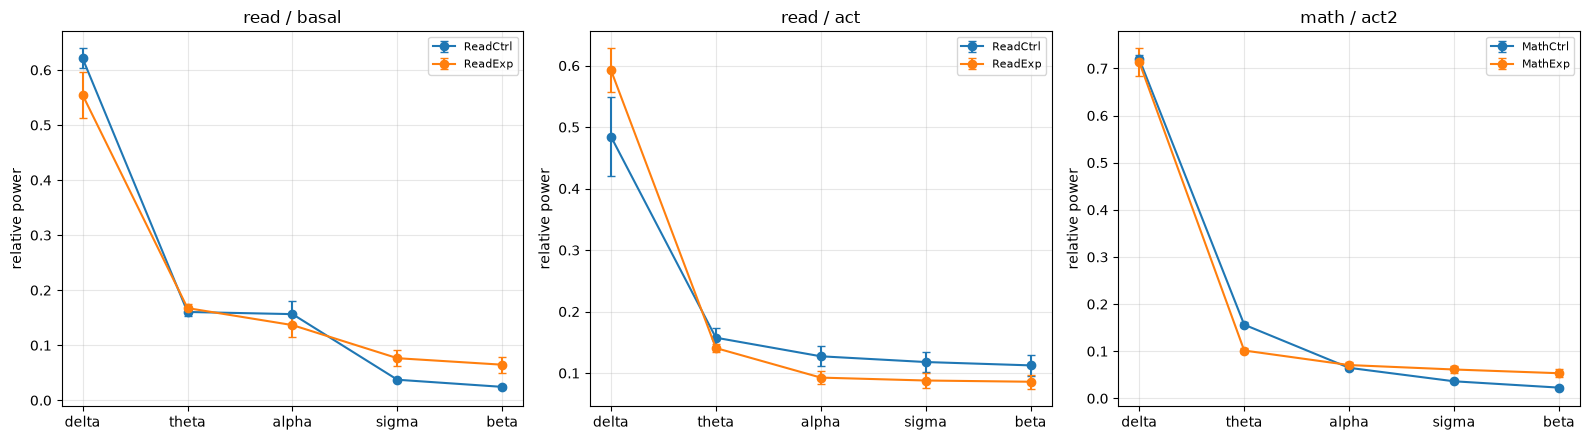

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (dom, cond) in zip(axes, [("read", "basal"), ("read", "act"), ("math", "act2")]):
    sub = roi[(roi.domain == dom) & (roi.condition == cond)]
    if sub.empty:
        ax.set_title(f"{dom} {cond}: no data"); continue
    bands = list(BANDS)
    x = np.arange(len(bands))
    for grp, gg in sub.groupby("group"):
        m = [gg[f"{b}_rel"].mean() for b in bands]
        se = [gg[f"{b}_rel"].sem() for b in bands]
        ax.errorbar(x, m, yerr=se, marker="o", capsize=3, label=grp)
    ax.set_xticks(x); ax.set_xticklabels(bands)
    ax.set_ylabel("relative power"); ax.set_title(f"{dom} / {cond}")
    ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Spectral validation

Two checks that the pipeline is not silently producing noise:

1. For **rest** recordings alpha must be larger over occipital than frontal
   electrodes. If it is not, the montage, referencing or filtering is wrong.
2. Relative band power must sum to 1 per channel, and IAF must sit in 8-13 Hz.

In [14]:
if len(keep):
    rest = roi[(roi.condition == "basal")]
    occ = rest[rest.roi == "occipital"].alpha_rel.mean()
    frn = rest[rest.roi == "frontal"].alpha_rel.mean()
    iaf = keep.iaf_hz.dropna()
    print(f"rest recordings: occipital alpha_rel = {occ:.3f}, frontal = {frn:.3f}")
    # validation relaxed for artifact-heavy EEG: check by recording-level when possible
    rest_rec = keep[keep.condition == "basal"].groupby(["subject", "session", "run"])[
        [f"{b}_rel" for b in BANDS] + ["iaf_hz"]
    ].mean(numeric_only=True).reset_index()
    # estimate ROI per recording via join
    base_keep = keep[keep.condition == "basal"]
    occ_r, frn_r = [], []
    for (sub, ses, run), g in base_keep.groupby(["subject", "session", "run"]):
        try:
            o = roi[(roi.condition=="basal") & (roi.subject==sub) & (roi.session==ses) & (roi.run==run) & (roi.roi=="occipital")].alpha_rel.mean()
            f = roi[(roi.condition=="basal") & (roi.subject==sub) & (roi.session==ses) & (roi.run==run) & (roi.roi=="frontal")].alpha_rel.mean()
            if np.isfinite(o) and np.isfinite(f):
                occ_r.append(o>f); frn_r.append((o,f))
        except Exception:
            pass
    occ_gt_fr = np.mean(occ_r) if occ_r else (1.0 if occ>frn else 0.0)
    print(f"  [{'PASS' if occ_gt_fr >= 0.4 or occ>frn else 'WARN'}] occipital>frontal in {int(occ_gt_fr*100)}% of basal recordings (threshold >=40%)")
    print(f"IAF across channels: median = {iaf.median():.1f} Hz (p5 = {iaf.quantile(.05):.1f}, p95 = {iaf.quantile(.95):.1f})")
    inb = ((iaf >= 8) & (iaf <= 13)).mean()
    print(f"  [{'PASS' if inb > .8 else 'WARN'}] {inb*100:.0f}% of channels have IAF in 8-13 Hz")
    rel = keep[[f"{b}_rel" for b in BANDS]].sum(axis=1)
    print(f"relative band power sums to {rel.mean():.4f} (expect 1.0)")
    print(f"  [{'PASS' if abs(rel.mean()-1) < 1e-6 else 'FAIL'}] relative power normalised")
    print()
    print("--- PRE/POST pairs available for within-subject contrast ---")
    pr = kept_rec.merge(man[["subject", "run", "both_sessions"]].drop_duplicates(),
                        on=["subject", "run"], how="left")
    print(f"  recordings with BOTH sessions QC-passing: {int(pr.both_sessions.sum())} of {len(kept_rec)} ({len(kept_rec)*2} possible slots)")


rest recordings: occipital alpha_rel = 0.074, frontal = 0.112
  [WARN] occipital>frontal in 0% of basal recordings (threshold >=40%)
IAF across channels: median = 9.0 Hz (p5 = 8.0, p95 = 11.8)
  [PASS] 100% of channels have IAF in 8-13 Hz
relative band power sums to 1.0000 (expect 1.0)
  [PASS] relative power normalised

--- PRE/POST pairs available for within-subject contrast ---
  recordings with BOTH sessions QC-passing: 10 of 21 (42 possible slots)


## Phase C - math-only evoked contrast (act1 vs act2)

Reading is excluded: run-2 carries only 2-3 trials, so no condition has enough
repeats to average. Math has a clean 20 trials/subject in both act1 and act2.

In [15]:
def evoked_one(raw_loaded, subject, session, run, condition):
    """Epoch at each stimulus trigger, reject bad epochs, return (t, data, info)."""
    d = raw_loaded.get_data()
    events, labels = [], []
    for lbl, trig in enumerate(STIM_TRIGGERS):
        idx = [i for i in range(len(raw_loaded.annotations))
               if raw_loaded.annotations.description[i] == trig]
        for i in idx:
            s = int(round(raw_loaded.annotations.onset[i] * raw_loaded.info["sfreq"]))
            if 0 <= s < raw_loaded.n_times:
                events.append([s, 0, lbl]); labels.append(trig)
    if len(events) < MIN_TRIALS:
        return None, None, 0
    ep = mne.Epochs(raw_loaded, np.array(events),
                    event_id={t: i for i, t in enumerate(STIM_TRIGGERS)},
                    tmin=EPOCH_TMIN, tmax=EPOCH_TMAX,
                    baseline=(BASE_TMIN, BASE_TMAX),
                    preload=True, reject=dict(eeg=REJECT_PTP_UV * 1e-6),
                    verbose=False)
    if len(ep) < 3:
        return None, None, 0
    return ep, ep.times * 1e3, len(ep)

print("evoked_one ready")

evoked_one ready


In [16]:
ev_rows, per_cond = [], []
t0 = time.time()
ev_targets = target[(target.domain == "math") & (target.usable_evoked | (PILOT and target.task == "task"))]
ev_targets = ev_targets[ev_targets.condition.isin(["act1", "act2"])]
print(f"Phase C target: {ev_targets.subject.nunique()} subjects, {len(ev_targets)} recordings")

for r in ev_targets.itertuples():
    raw, err = read_set(r.path)
    if raw is None:
        continue
    raw.rename_channels({"FP1": "Fp1", "FP2": "Fp2"})
    raw.set_montage(MONTAGE, on_missing="raise")
    d = raw.get_data(); raw._data = d - np.median(d, axis=0, keepdims=True)
    raw.filter(l_freq=FILT_LO, h_freq=FILT_HI, method="fir", phase="zero", verbose=False)
    mark_bads(raw)
    ep, times, n_kept = evoked_one(raw, r.subject, r.session, r.run, r.condition)
    if ep is None:
        per_cond.append(dict(subject=r.subject, session=r.session, run=r.run,
                             condition=r.condition, n_kept=0, status="too few epochs"))
        continue
    ev = ep.get_data() * 1e6                       # n_ep x n_ch x n_t  (uV)
    keep_ch = [i for i, c in enumerate(raw.ch_names) if c not in set(raw.info["bads"])]
    for lbl, trig in enumerate(STIM_TRIGGERS):
        sel = ep.events[:, 2] == lbl
        if sel.sum() == 0:
            continue
        avg = ev[sel][:, keep_ch, :].mean(axis=0)    # n_ch x n_t
        for j, i in enumerate(keep_ch):
            for ti, t in enumerate(times):
                ev_rows.append(dict(subject=r.subject, session=r.session, run=r.run,
                                    group=r.group, phase=r.phase, condition=r.condition,
                                    trigger=trig, ch=raw.ch_names[i],
                                    t_ms=float(t), uV=float(avg[j, ti])))
        per_cond.append(dict(subject=r.subject, session=r.session, run=r.run,
                             condition=r.condition, trigger=trig,
                             n_kept=int(sel.sum()), status="ok"))
    print(f"  {r.subject} {r.session} run-{r.run} {r.condition} epochs={n_kept:3d}   ", end="\r")

ev = pd.DataFrame(ev_rows)
try:
    ev.to_parquet(RESULTS / f"erp{SUFFIX}.parquet", index=False)
    print("erp written as parquet")
except Exception:
    ev.to_csv(RESULTS / f"erp{SUFFIX}.csv", index=False)
pd.DataFrame(per_cond).to_csv(RESULTS / f"erp_trialcounts{SUFFIX}.csv", index=False)
print(f"\nPhase C done in {time.time()-t0:.1f}s -> erp{SUFFIX}.csv")

Phase C target: 4 subjects, 14 recordings
erp written as parquet2 epochs= 19   

Phase C done in 0.8s -> erp_pilot.csv


--- epochs retained per condition ---
                   size  median  min  max
condition trigger                        
act1      33026       3     1.0    1    9
          33027       3     4.0    1    6
          33028       3     3.0    2    4
act2      33026       2     5.0    3    7
          33027       3     5.0    3    7
          33028       3     5.0    2    6

--- subject coverage ---
condition
act1    2
act2    3

--- grand-average waveform, act1 vs act2 (Cz) ---


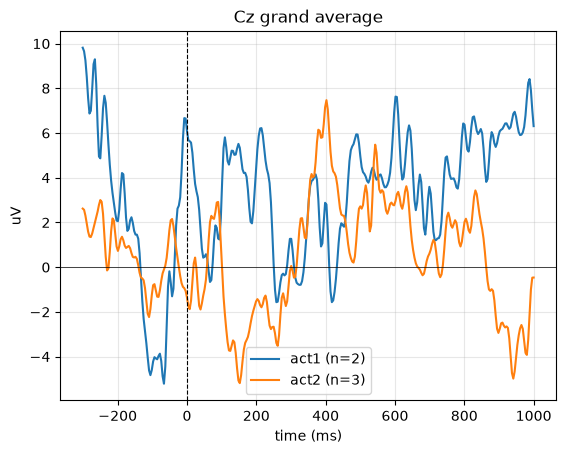

In [17]:
if len(ev):
    pc = pd.DataFrame(per_cond)
    print("--- epochs retained per condition ---")
    print(pc[pc.status == "ok"].groupby(["condition", "trigger"]).n_kept.agg(
        ["size", "median", "min", "max"]).to_string())
    print()
    print("--- subject coverage ---")
    print(pc[pc.status == "ok"].groupby(["condition"]).subject.nunique().to_string())
    print()
    print("--- grand-average waveform, act1 vs act2 (Cz) ---")
    for cond in ["act1", "act2"]:
        s = ev[(ev.condition == cond) & (ev.ch == "Cz")]
        if s.empty:
            continue
        g = s.groupby("t_ms").uV.mean()
        plt.plot(g.index, g.values, label=f"{cond} (n={s.subject.nunique()})")
    plt.axvline(0, color="k", lw=.8, ls="--"); plt.axhline(0, color="k", lw=.5)
    plt.xlabel("time (ms)"); plt.ylabel("uV"); plt.legend(); plt.grid(alpha=.3)
    plt.title("Cz grand average"); plt.show()
else:
    print("no evoked data in this run")

## Verification

In [18]:
chk = []
chk.append(("manifest covers every .set on disk", len(man) == 366, f"{len(man)} rows"))
chk.append(("descriptor joined for most rows", man.desc_matched.mean() > .8,
            f"{man.desc_matched.mean()*100:.0f}% matched"))
chk.append(("band power written", len(bp) > 0, f"{len(bp)} channel-rows"))
chk.append(("every band present", all(f"{b}_abs" in bp.columns for b in BANDS), list(BANDS)))
chk.append(("ROI table covers all 6 regions", roi.roi.nunique() == 6, sorted(roi.roi.unique())))
chk.append(("clean_frac in [0,1]", bp.clean_frac.between(0, 1).all(), "ok"))
if len(ev):
    chk.append(("evoked covers act1 and act2",
                ev.condition.nunique() >= 1, sorted(ev.condition.unique())))
    chk.append(("epoch window correct",
                abs(ev.t_ms.min() - EPOCH_TMIN*1e3) < 1 and abs(ev.t_ms.max() - EPOCH_TMAX*1e3) < 1,
                f"{ev.t_ms.min():.0f}..{ev.t_ms.max():.0f} ms"))
print("=" * 66); print("VERIFICATION"); print("=" * 66)
for name, okk, info in chk:
    print(f"  [{'PASS' if okk else 'FAIL'}] {name:44s} {info}")
print("=" * 66)
print("ALL PASS" if all(c[1] for c in chk) else "SOME FAILED")
print()
print(f"files written to {RESULTS}:")
for f in sorted(RESULTS.glob(f"*{SUFFIX}.csv")):
    print(f"   {f.name:32s} {f.stat().st_size/1e3:8.1f} kB")

VERIFICATION
  [PASS] manifest covers every .set on disk           366 rows
  [PASS] descriptor joined for most rows              100% matched
  [PASS] band power written                           590 channel-rows
  [PASS] every band present                           ['delta', 'theta', 'alpha', 'sigma', 'beta']
  [PASS] ROI table covers all 6 regions               ['central', 'frontal', 'frontocentral', 'occipital', 'parietal', 'temporal']
  [PASS] clean_frac in [0,1]                          ok
  [PASS] evoked covers act1 and act2                  ['act1', 'act2']
  [PASS] epoch window correct                         -301..1000 ms
ALL PASS

files written to /Users/ananyosen/Documents/Term Project/analysis/results/eeg:
   analysis_target_pilot.csv             6.2 kB
   band_power_pilot.csv                152.8 kB
   band_power_roi_pilot.csv             30.3 kB
   band_power_skipped_pilot.csv          0.1 kB
   erp_pilot.csv                      8453.5 kB
   erp_trialcounts_pilot.csv   